# <a id='toc1_'></a>[Ingeniería de características](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Ingeniería de características](#toc1_)    
  - [Carga del dataset](#toc1_1_)    
  - [Variable objetivo](#toc1_2_)    
  - [Extracción de la Marca (`brand`)](#toc1_3_)    
  - [Duplicados con etiquetas contradictorias](#toc1_4_)    
  - [Agrupación de clases minoritarias](#toc1_5_)    
  - [Codificación de etiquetas y exportación](#toc1_6_)    
  - [Resumen](#toc1_7_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook definimos qué problema vamos a resolver y preparamos las etiquetas para los experimentos. Partimos del dataset limpio del EDA (`styles_clean.csv`).

La idea final es una app en la que se sube la imagen de un producto y nos dice de qué tipo es. Por eso, el modelo solo va a recibir **la imagen** como entrada y las columnas del catálogo serán las etiquetas a predecir. Cualquier información que no tengamos al subir una imagen (nombre, marca...) no la podemos usar como entrada.

**Objetivos:**
1. Elegir la variable objetivo del primer modelo (`masterCategory`).
2. Extraer la marca (`brand`) y ver si aporta algo.
3. Limpiar etiquetas: duplicados con etiquetas contradictorias.
4. Agrupar las clases con muy pocos ejemplos en `Other`.
5. Calcular el hash de cada imagen para poder separar train/test sin duplicados en `03_preprocessing`.
6. Exportar el dataset etiquetado (`styles_labeled.csv`) y el mapeo de clases (`label_mappings.json`).

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from sklearn.metrics import mutual_info_score

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import INTERIM_DATA_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR, IMAGES_DIR, RANDOM_STATE
from fashion_mlops.utils.visualizations import plot_heatmap_correlation, show_images, variable_conflicts
from fashion_mlops.features.build_features import clean_brand_column
from fashion_mlops.data.make_dataset import add_file_hashes, group_rare_classes

## <a id='toc1_1_'></a>[Carga del dataset](#toc0_)

In [2]:
df = pd.read_csv(INTERIM_DATA_DIR / "styles_clean.csv")

print(f"Dataset limpio cargado: {df.shape[0]} filas, {df.shape[1]} columnas.")

Dataset limpio cargado: 44419 filas, 10 columnas.


## <a id='toc1_2_'></a>[Variable objetivo](#toc0_)

Las columnas que podríamos predecir a partir de la imagen son `gender`, `masterCategory`, `subCategory`, `articleType`, `season` y `usage`. Vamos a compararlas:

In [3]:
candidates = ["masterCategory", "gender", "subCategory", "articleType", "season", "usage"]

summary = pd.DataFrame({
    "n_clases": [df[col].nunique() for col in candidates],
    "clase_mayoritaria": [df[col].value_counts().index[0] for col in candidates],
    "% mayoritaria": [df[col].value_counts(normalize=True).iloc[0] * 100 for col in candidates],
    "clases < 50 ejemplos": [(df[col].value_counts() < 50).sum() for col in candidates],
}, index=candidates).round(1)

summary

,n_clases,clase_mayoritaria,% mayoritaria,clases < 50 ejemplos
masterCategory,7,Apparel,48.2,2
gender,5,Men,49.8,0
subCategory,45,Topwear,34.7,15
articleType,142,Tshirts,15.9,72
season,4,Summer,48.4,0
usage,8,Casual,78.2,3


- `masterCategory`: pocas clases y muy distintas a simple vista (ropa, calzado, accesorios...). **Será la variable objetivo de nuestro primer modelo.**
- `gender`, `subCategory` y `articleType`: también se pueden ver en la imagen, las dejamos para experimentos posteriores. En `subCategory` y `articleType` habrá que agrupar muchas clases con pocos ejemplos.
- `season` y `usage`: difíciles de adivinar solo con la imagen y muy desbalanceadas (78 % `Casual`), así que las descartamos como objetivo.

El resto de columnas (`baseColour`, `year`, `productDisplayName`) no las usaremos como objetivo ni como entrada.

## <a id='toc1_3_'></a>[Extracción de la Marca (`brand`)](#toc0_)

Extraemos la marca a partir del nombre comercial (`productDisplayName`).


In [4]:
df[["productDisplayName", "gender", "baseColour"]]

,productDisplayName,gender,baseColour
0,Turtle Check Men Navy Blue Shirt,Men,Navy Blue
1,Peter England Men Party Blue Jeans,Men,Blue
2,Titan Women Silver Watch,Women,Silver
3,Manchester United Men Solid Black Track Pants,Men,Black
4,Puma Men Grey T-shirt,Men,Grey
...,...,...,...
44414,Gas Men Caddy Casual Shoe,Men,White
44415,Lotto Men's Soccer Track Flip Flop,Men,Red
44416,Puma Men Graphic Stellar Blue Tshirt,Men,Blue
44417,Rasasi Women Blue Lady Perfume,Women,Blue


Observando la estructura de `productDisplayName`, nos damos cuenta de que el nombre se construye en muchos casos como:
```py
[brand] [gender] [baseColour] [descripción]
```
Sin embargo, los datos contienen excepciones, erratas, variantes ortográficas y marcas que empiezan por palabras que también pueden ser colores o categorías. 

Considerando todas estas casuísticas llegamos a la función `clean_brand_column()` que combina tres niveles de reglas:
1. Reglas estructurales: cortar por palabras de género, público, color o descripción.
2. Reglas de normalización: corregir mayúsculas, prefijos, signos, espacios y pequeñas erratas.
3. Excepciones manuales: resolver marcas ambiguas o variantes que no pueden inferirse con seguridad automáticamente.


In [5]:
clean_brand_column(df, column="brand")

Comprobamos cómo ha quedado la variable:

In [6]:
brand_counts = df["brand"].value_counts()

print(f"Marcas distintas: {brand_counts.size}")
brand_counts.head(10)

Marcas distintas: 386


brand
NIKE                         2364
PUMA                         2186
ADIDAS                       2081
UNITED COLORS OF BENETTON    1401
LEE                           814
FILA                          800
FABINDIA                      751
CATWALK                       743
GINI AND JONY                 722
MYNTRA                        717
Name: count, dtype: int64

¿Qué valor aporta realmente `brand` a nuestro problema?

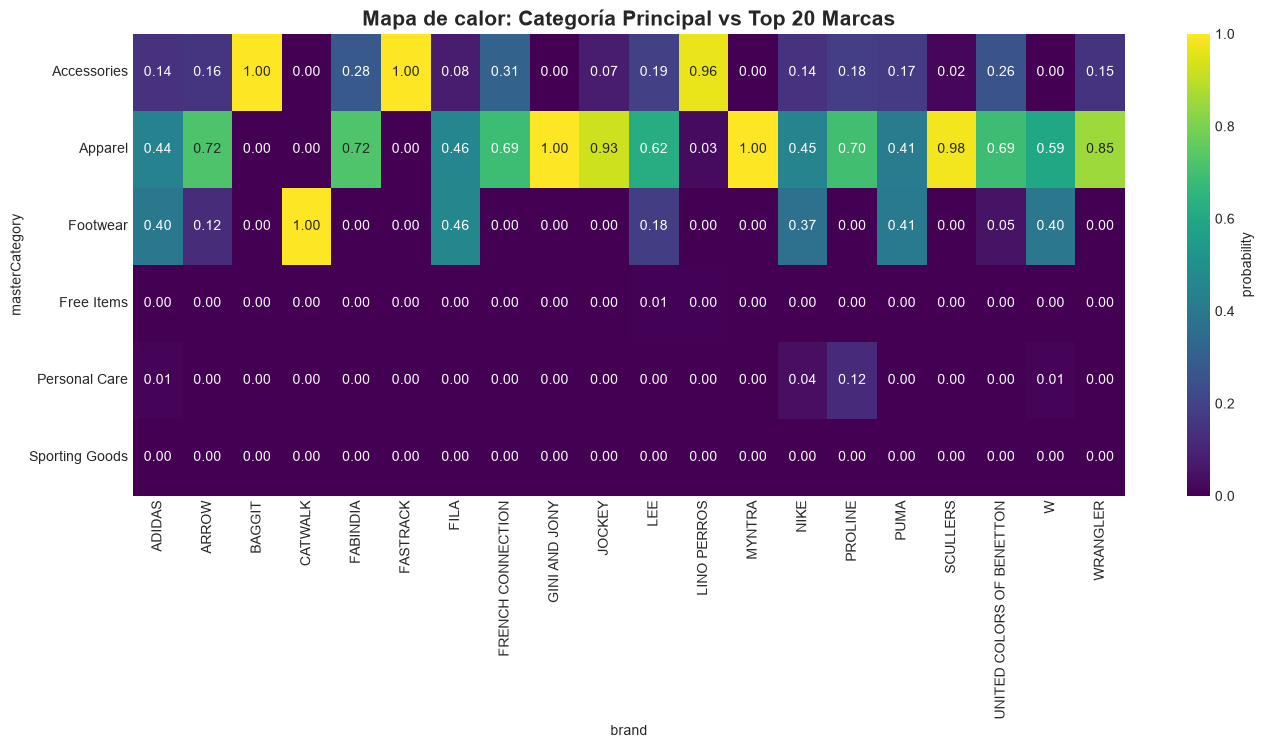

In [7]:
top_brands = brand_counts.nlargest(20).index

plot_heatmap_correlation(
    df[df["brand"].isin(top_brands)],
    "masterCategory",
    "brand",
    figsize=(16, 6),
    title="Mapa de calor: Categoría Principal vs Top 20 Marcas",
    normalize="columns"
)

Muchas marcas se concentran en una sola categoría (CATWALK en Footwear, FASTRACK y BAGGIT en Accessories), mientras que otras como NIKE, ADIDAS o PUMA se reparten entre Apparel y Footwear. Medimos esta relación con la información mutua:

In [8]:
df_mi = df[["brand", "masterCategory"]].dropna()

mi = mutual_info_score(df_mi["brand"], df_mi["masterCategory"])
H_target = entropy(df_mi["masterCategory"].value_counts(normalize=True))

print(f"Información mutua brand - masterCategory: {mi:.4f}")
print(f"Entropía de masterCategory: {H_target:.4f}")
print(f"Proporción MI / H(target): {mi / H_target:.4f}")

Información mutua brand - masterCategory: 0.8025
Entropía de masterCategory: 1.2028
Proporción MI / H(target): 0.6672


La marca explica alrededor de dos tercios de la incertidumbre de `masterCategory`, así que está muy relacionada con la variable objetivo. Pero esto pasa porque sale del nombre del producto, que ya "lleva" la categoría dentro. Cuando un usuario suba una imagen a la app no vamos a tener ni el nombre ni la marca, así que **no usamos `brand` como entrada del modelo**. Nos la guardamos como metadato para mostrar productos similares en la app.

## <a id='toc1_4_'></a>[Duplicados con etiquetas contradictorias](#toc0_)

En el EDA vimos que hay imágenes idénticas (mismo hash) con etiquetas distintas. Calculamos el hash de cada imagen y nos centramos en los conflictos de nuestra variable objetivo, `masterCategory`:

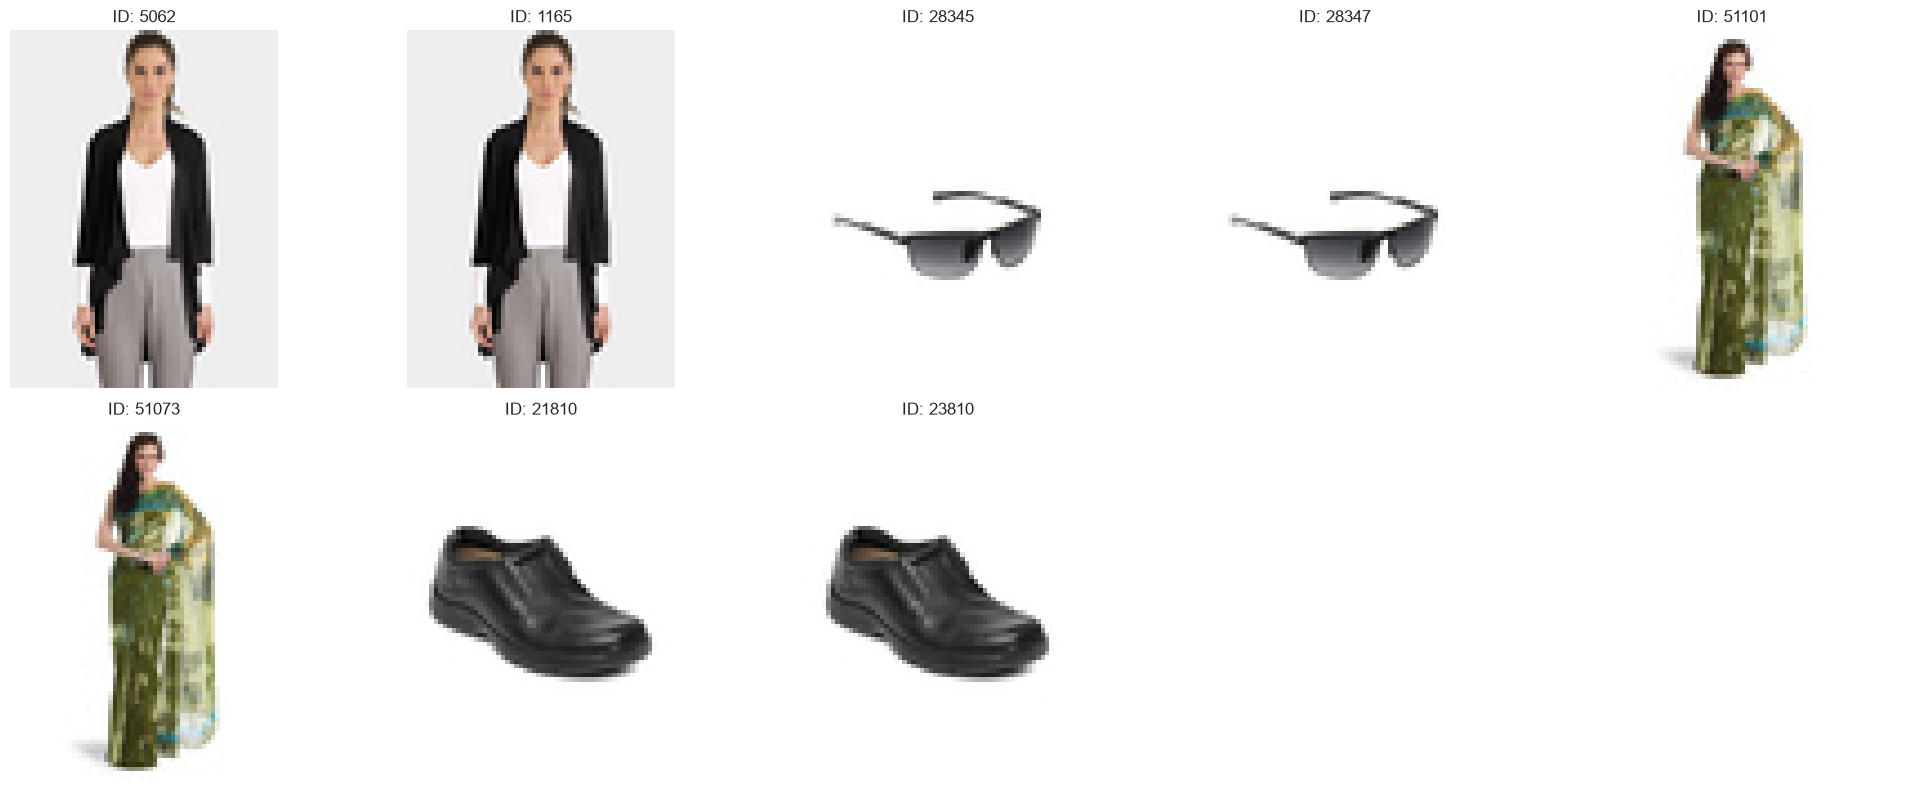

Imágenes en grupos con masterCategory conflictivo: 8 
Porcentaje sobre el dataset: 0.018%


,file_hash,id,masterCategory,subCategory,articleType,productDisplayName
23759,0681830b0b2c248fe2e3f3f4c419d50c,5062,Accessories,Watches,Watches,Being Human Men Black Dial Steel Plated Strap ...
16342,0681830b0b2c248fe2e3f3f4c419d50c,1165,Apparel,Topwear,Tshirts,Nike Mean Team India Cricket Jersey
8298,80a87114757ad770dbb029914b4c2df2,28345,Accessories,Eyewear,Sunglasses,Idee Men Black Sunglasses
31158,80a87114757ad770dbb029914b4c2df2,28347,Free Items,Free Gifts,Free Gifts,IDEE Men Black Sunglasses
36821,99acfb864e2b3b0bfa45ccfa52b4a087,51101,Apparel,Saree,Sarees,Satya Paul Green Printed Saree
40959,99acfb864e2b3b0bfa45ccfa52b4a087,51073,Free Items,Free Gifts,Free Gifts,Satya Paul Olive Saree
13939,df47bd490230a704290cf8f2b82ca1dc,21810,Accessories,Wallets,Wallets,Fossil Men Hood Traveller Brown Wallet
22541,df47bd490230a704290cf8f2b82ca1dc,23810,Footwear,Shoes,Casual Shoes,Clarks Men Black Supa Step Casual Shoes


In [9]:
df["file_hash"] = add_file_hashes(df, IMAGES_DIR)

conflicts = variable_conflicts(df, "masterCategory", path=RAW_DATA_DIR)
conflicts[["file_hash", "id", "masterCategory", "subCategory", "articleType", "productDisplayName"]]

Son 4 parejas. Seguimos el mismo criterio que con los registros de prueba del EDA: si la imagen ya está en el dataset con la etiqueta correcta, eliminamos el registro mal etiquetado; si ninguna etiqueta encaja con la imagen, eliminamos los dos.

| Imagen | Registros | Decisión |
|---|---|---|
| Mujer con chaqueta negra | `1165` camiseta de críquet / `5062` reloj | Eliminar los dos |
| Gafas de sol | `28345` Sunglasses / `28347` Free Gifts | Eliminar `28347` |
| Sari | `51101` Saree / `51073` Free Gifts | Eliminar `51073` |
| Zapato | `23810` Casual Shoes / `21810` cartera | Eliminar `21810` |

In [10]:
ids_to_drop = [1165, 5062, 28347, 51073, 21810]

df = df[~df["id"].isin(ids_to_drop)].reset_index(drop=True)

print(f"Registros tras eliminar los conflictos: {len(df)}")

Registros tras eliminar los conflictos: 44414


## <a id='toc1_5_'></a>[Agrupación de clases minoritarias](#toc0_)

Veamos cuántos ejemplos tiene cada clase de `masterCategory`:

In [11]:
df["masterCategory"].value_counts()

masterCategory
Apparel           21392
Accessories       11271
Footwear           9219
Personal Care      2403
Free Items          103
Sporting Goods       25
Home                  1
Name: count, dtype: int64

`Home`, `Sporting Goods` y `Free Items` tienen muy pocos ejemplos para que el modelo las aprenda (y en test apenas quedarían unas pocas imágenes para evaluarlas). Además, `Free Items` son regalos promocionales, así que pueden ser cualquier cosa:

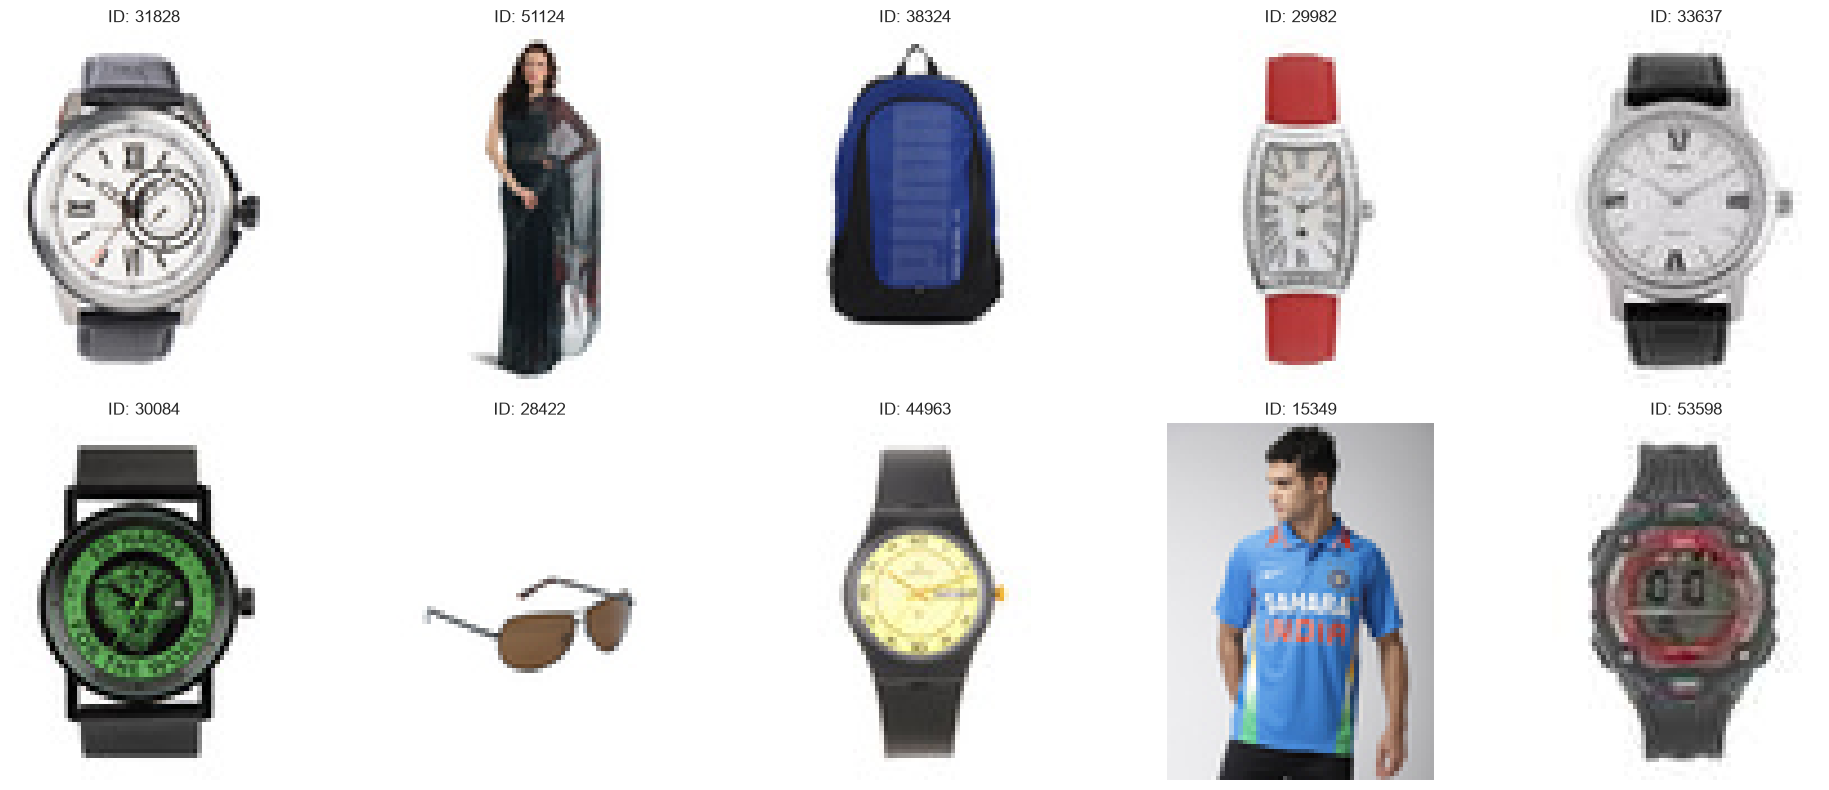

In [12]:
show_images(df=df[df["masterCategory"] == "Free Items"], image_dir=IMAGES_DIR, n_images=10, random_state=RANDOM_STATE)

En lugar de eliminarlas, las juntamos en una clase `Other`. Así la app puede responder "otro" en vez de forzar una categoría equivocada. Guardamos el resultado en una columna nueva para no perder la etiqueta original:

In [13]:
df["masterCategory_grouped"] = group_rare_classes(
    df["masterCategory"],
    classes=["Home", "Sporting Goods", "Free Items"]
)

df["masterCategory_grouped"].value_counts()

masterCategory_grouped
Apparel          21392
Accessories      11271
Footwear          9219
Personal Care     2403
Other              129
Name: count, dtype: int64

## <a id='toc1_6_'></a>[Codificación de etiquetas y exportación](#toc0_)

El modelo necesita las clases como números. Creamos el mapeo clase → índice y lo guardamos en un JSON, porque también lo necesitaremos en la app para traducir la predicción a texto.

In [14]:
classes = sorted(df["masterCategory_grouped"].unique())
label_mappings = {"masterCategory": {label: idx for idx, label in enumerate(classes)}}

df["masterCategory_idx"] = df["masterCategory_grouped"].map(label_mappings["masterCategory"])

label_mappings

{'masterCategory': {'Accessories': 0,
  'Apparel': 1,
  'Footwear': 2,
  'Other': 3,
  'Personal Care': 4}}

In [15]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(PROCESSED_DATA_DIR / "styles_labeled.csv", index=False)

with open(PROCESSED_DATA_DIR / "label_mappings.json", "w") as f:
    json.dump(label_mappings, f, indent=2)

print(f"Dataset exportado: {df.shape[0]} filas, {df.shape[1]} columnas.")
print(f"Columnas: {df.columns.to_list()}")

Dataset exportado: 44414 filas, 14 columnas.
Columnas: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'brand', 'file_hash', 'masterCategory_grouped', 'masterCategory_idx']


## <a id='toc1_7_'></a>[Resumen](#toc0_)

- Problema: clasificar la imagen de un producto en su `masterCategory`, con 5 clases (Accessories, Apparel, Footwear, Other, Personal Care).
- `brand` no se usa como entrada del modelo, la guardamos para mostrar productos similares en la app.
- Hemos eliminado 5 registros duplicados con etiquetas contradictorias.
- Exportamos `styles_labeled.csv` (con `file_hash` para hacer el split sin duplicados) y `label_mappings.json`.

En `03_preprocessing` dividiremos en train/val/test y prepararemos las imágenes para el modelo.